# **Skincare Product Review Analysis**

This notebook outlines the plan for analyzing thousands of skincare product reviews to extract actionable business insights. It audits and cleans the raw data first, and exports all results as data files that a dashboard can load later.

## **1. Background & Project Objectives**

**Problem:** A store or brand with many products struggles to monitor each product's performance efficiently. Which products are customer favorites? Which ones disappoint? What recurring themes appear in the complaints and the praise? The answers are buried in thousands of unstructured reviews.

**Objectives:**
- **Audit and clean** the raw reviews before any analysis: scraper artifacts, duplicates, resale posts, personal data (phone numbers, handles, links), inconsistent product names, and unparsed dates.
- Perform **sentiment classification** ('Positive', 'Neutral', 'Negative') on all reviews, based on the existing Rating column.
- Identify the **best-performing** and **worst-performing** products using a **fair ranking** that accounts for how many reviews each product has.
- Use **Google Gemini** to **summarize** the main reasons behind positive sentiment for the top 3 products and negative sentiment for the bottom 3 products.
- Provide **strategic recommendations** for product management and marketing based on the analysis.
- **Export** every result needed by the dashboard (cleaned reviews, product ranking, AI summaries, overall statistics).

**Dataset:** [Skincare Review](https://www.kaggle.com/datasets/hafidahmusthaanah/skincare-review) on Kaggle.

## **2. Analysis Process**

1. **Data Audit:** Measure the data-quality problems in the raw data (nothing is modified yet).
2. **Data Preprocessing:** Apply the cleaning rules in a fixed order and log how many rows each rule changes: remove rows without a Review or Rating, validate ratings, strip the scraper's `... Read more` suffix, normalize whitespace and product names, remove duplicates, mask personal data, remove resale posts, parse dates robustly, then extract helpful fields (skin type, age group, post date, recommendation flag, review length).
3. **Rule-Based Sentiment Classification:** Apply a simple rule to create a new `Sentiment` column. Reviews with a Rating of 4 or 5 are 'Positive', a Rating of 3 is 'Neutral', and a Rating of 1 or 2 is 'Negative'.
4. **Statistical Analysis & Visualization:**
   - Create a *bar chart* of the overall sentiment distribution (Positive, Negative, Neutral) across all products.
   - Build a **summary table** showing each product's review count, average rating, and sentiment percentage distribution.
5. **Fair Product Ranking:** Rank products with a **minimum review count** and a **Bayesian (weighted) average rating**, then plot the **top 10** and **bottom 10 products**.
6. **Theme Summarization with AI:**
   - For the 3 highest-ranked and 3 lowest-ranked products, group their reviews by sentiment. The Google Gemini model then summarizes the most common themes: praise for the top products and complaints for the bottom products.
7. **Export for the Dashboard:** Save all results, including the preprocessing log, into a `dashboard_data/` folder so the dashboard never has to re-run the analysis or call the AI again.

## **3. Potential Insights & Findings**

- "Products X, Y, and Z consistently receive the lowest ratings. The AI concludes that the main complaint for all three is a 'sticky and heavy texture', which points to a potential problem with a shared formulation base."
- "Although the dataset contains many products, most of the positive sentiment comes from a few 'hero products', all praised for their 'brightening effect'."
- "The AI-summarized complaint for Product A is 'causes breakouts on oily skin'. This indicates a mismatch between the product and a specific customer segment."
- "3-star (Neutral) products are often not poor in quality, but suffer from mismatched expectations. The AI can surface review themes such as 'good, but not as effective as advertised'."

## **4. Recommendations & Conclusion**

- **Product Management & Inventory:** Review the formulation of the worst-performing products, or even discontinue them, to avoid further customer disappointment.
- **Marketing:** Launch a "Customer Favorites" campaign focused on the highest-ranked products, and use the AI-generated praise summaries as promotional material.
- **New Product Development:** Develop new products that directly address the most common complaints found in the poorly performing products.

## **Step 1: Import Libraries and Load the Data**

Next, import the libraries needed for data analysis and visualization, then download the dataset from Kaggle and load it into a DataFrame.

> The preview below hides `UserName` and `Recommend` (the latter contains the username), so no reviewer handles end up in the saved notebook output.

In [2]:
import json
import os
import re
import warnings
from datetime import datetime, timezone
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Suppress non-critical warnings to keep the output clean
warnings.filterwarnings("ignore")
# Show all columns and use a wider display when printing DataFrames
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("📚 Libraries imported.")

# Download the skincare review dataset from Kaggle Hub and load the CSV into a DataFrame
DATASET_ID = "hafidahmusthaanah/skincare-review"
try:
    path = kagglehub.dataset_download(DATASET_ID)
    df = pd.read_csv(os.path.join(path, "00. Review.csv"))
except FileNotFoundError:
    print("❌ ERROR: Dataset file not found. Please check that the file path is correct.")
    raise

print(f"✔️ Dataset loaded successfully. Total rows: {len(df)}.")
print("\nSample data:")
print(df.drop(columns=["UserName", "Recommend"], errors="ignore").head())

📚 Libraries imported.
✔️ Dataset loaded successfully. Total rows: 8646.

Sample data:
          Product          SkinCond_Age     PostDate                                             Review  Rating
0  Perfect 3D Gel               35 - 39  12 Jul 2020  Di aku beneran kerja. Melembabkan bgt. Tp gak ...       5
1  Perfect 3D Gel       Normal, 19 - 24  31 May 2020  ga cocok bgttt bikin muka bruntusan dan lgsg m...       2
2  Perfect 3D Gel  Combination, 19 - 24  30 Jul 2020  [SOLD]baru pertama kali nyoba dan beli karna l...       2
3  Perfect 3D Gel          Dry, 30 - 34  12 Jul 2020  enak sih di mukaku, yg tadinya kering jd lemba...       3
4  Perfect 3D Gel         Oily, 19 - 24  15 Jul 2020  SOLD OUT [PRELOVED] Halo aku preloved ini ya, ...       3


## **Step 2: Data Audit and Cleaning Rules**

Before changing anything, we measure what is wrong with the raw data. Scraped review text usually has problems that silently distort the analysis, and some of them also affect the AI summaries and the dashboard.

| Check | Why it matters | Rule applied in Step 3 |
|---|---|---|
| Missing `Review` / `Rating`, ratings outside 1–5 | Cannot be analyzed or ranked | Drop the row |
| Review text cut off by the scraper (ends with `... Read more`) | The suffix is not part of the review and pollutes AI prompts and search | Strip the suffix and keep a `Review_Truncated` flag, because the text itself is incomplete |
| Extra spaces, tabs, line breaks | Breaks exact matching and de-duplication | Collapse to single spaces |
| Product names that differ only by letter case or spacing | The same product is split into several ranking entries with fewer reviews each | Merge them under the most frequent spelling |
| Exact duplicate reviews (same `Product`, `UserName`, `Review`) | Counts the same opinion twice | Keep the first occurrence (`DROP_DUPLICATES`) |
| Phone numbers, `@handles`, links, e-mail addresses inside the text | Personal data that should not be exported or published | Replace with `[PHONE]`, `[HANDLE]`, `[URL]`, `[EMAIL]` (`MASK_PII`) |
| Resale posts ("preloved", "jual", price or contact details) | A sales listing is not product feedback | Drop rows with sale intent **and** a price or contact detail (`DROP_RESALE_POSTS`) |
| Dates that cannot be parsed | Missing months break time trends | Normalize month names (e.g. Indonesian or `Sept`) and retry; keep the row either way |

The detection rules for resale posts are heuristics, so the audit prints a few masked examples. Review them, and set the switches below to `False` if you prefer to keep a rule's rows.

In [3]:
# --- Preprocessing switches (tunable) ---
DROP_DUPLICATES = True     # remove exact duplicate reviews
MASK_PII = True            # replace phone numbers, @handles, links and e-mails in the review text
DROP_RESALE_POSTS = True   # remove resale listings (sale intent + price or contact detail)
MIN_REVIEW_CHARS = 10      # reviews shorter than this (after cleaning) are dropped
DEDUP_COLUMNS = ["Product", "UserName", "Review"]

# --- Patterns ---
WHITESPACE_RE = re.compile(r"\s+")
READ_MORE_RE = re.compile(r"\s*\.{3}\s*Read more\s*$", re.IGNORECASE)  # scraper artifact at the end of the text

URL_RE = re.compile(r"(?:https?://|www\.)\S+", re.IGNORECASE)
EMAIL_RE = re.compile(r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+")
PHONE_RE = re.compile(r"(?<![\w+])(?:\+?62|0)8\d{1,3}(?:[\s.\-]?\d){6,10}(?!\d)")  # Indonesian mobile numbers
HANDLE_RE = re.compile(r"(?<![\w.@])@[A-Za-z0-9_.]{2,30}")

# Resale post = sale intent AND (a price OR a way to contact the seller)
SELL_RE = re.compile(
    r"pre-?loved|\bwts\b|\bdijual\b|\bmau\s+(?:di\s*)?jual\b"
    r"|\b(?:ingin|lagi|aku|saya)\s+(?:me)?jual\b|\bjual\s+(?:aja|saja|nih)\b|^\W*sold\b",
    re.IGNORECASE,
)
PRICE_RE = re.compile(r"(?<![\w.])\d{1,3}(?:[.,]\d{3})*\s?(?:rb|ribu|k)\b|\brp\.?\s?\d", re.IGNORECASE)
CONTACT_RE = re.compile(r"\[(?:PHONE|HANDLE|URL)\]|\b(?:wa|whatsapp|dm|cod)\b", re.IGNORECASE)

# Month names that %b cannot read -> English abbreviations (Indonesian, long names, "Sept")
MONTHS = {
    "jan": "Jan", "januari": "Jan", "january": "Jan", "feb": "Feb", "februari": "Feb", "february": "Feb",
    "mar": "Mar", "maret": "Mar", "march": "Mar", "apr": "Apr", "april": "Apr", "mei": "May", "may": "May",
    "jun": "Jun", "juni": "Jun", "june": "Jun", "jul": "Jul", "juli": "Jul", "july": "Jul",
    "agu": "Aug", "agt": "Aug", "agus": "Aug", "agustus": "Aug", "aug": "Aug", "august": "Aug",
    "sep": "Sep", "sept": "Sep", "september": "Sep", "okt": "Oct", "oktober": "Oct", "oct": "Oct", "october": "Oct",
    "nov": "Nov", "nop": "Nov", "november": "Nov", "des": "Dec", "desember": "Dec", "dec": "Dec", "december": "Dec",
}


# --- Helpers ---
def normalize_text(text):
    """Collapse any run of whitespace (spaces, tabs, line breaks) into one space and trim the ends."""
    return WHITESPACE_RE.sub(" ", str(text)).strip()


def mask_pii(text):
    """Replace links, e-mails, phone numbers and @handles with placeholders."""
    text = URL_RE.sub("[URL]", text)
    text = EMAIL_RE.sub("[EMAIL]", text)
    text = PHONE_RE.sub("[PHONE]", text)
    return HANDLE_RE.sub("[HANDLE]", text)


def is_resale_post(masked_text):
    """True when the text announces a sale AND names a price or a contact channel (expects masked text)."""
    return bool(SELL_RE.search(masked_text) and (PRICE_RE.search(masked_text) or CONTACT_RE.search(masked_text)))


def canonical_product_names(products):
    """Map names that differ only by case/spacing to the most frequent spelling (ties: alphabetical)."""
    cleaned = products.astype(str).map(normalize_text)
    key = cleaned.str.casefold()
    spelling = (
        pd.DataFrame({"key": key, "name": cleaned})
        .groupby(["key", "name"]).size().rename("n").reset_index()
        .sort_values(["key", "n", "name"], ascending=[True, False, True])
        .drop_duplicates("key")
        .set_index("key")["name"]
    )
    return key.map(spelling)


def parse_post_dates(raw):
    """Parse dates like '12 Jul 2020'; retry with normalized month names; unparseable values become NaT."""
    text = raw.astype("string").str.strip()
    parsed = pd.to_datetime(text, format="%d %b %Y", errors="coerce")
    retry = parsed.isna() & text.notna()
    if retry.any():
        fixed = text[retry].map(lambda s: re.sub(r"[A-Za-z]+", lambda m: MONTHS.get(m.group(0).lower(), m.group(0)), s))
        parsed[retry] = pd.to_datetime(fixed, format="%d %b %Y", errors="coerce")
    return parsed

In [4]:
print("🔎 Auditing the raw data (nothing is modified in this step)...")

review_text = df["Review"].fillna("").astype(str)
masked_text = review_text.map(mask_pii)
parsed_dates = parse_post_dates(df["PostDate"])
rating_ok = df["Rating"].dropna()

audit = {
    "Rows loaded": len(df),
    "Missing Review": int(df["Review"].isna().sum()),
    "Missing Rating": int(df["Rating"].isna().sum()),
    "Rating outside 1-5": int((~rating_ok.between(1, 5)).sum()),
    "Truncated by scraper ('... Read more')": int(review_text.str.contains(READ_MORE_RE).sum()),
    "Extra whitespace in review": int((review_text != review_text.map(normalize_text)).sum()),
    "Exact duplicates (Product + UserName + Review)": int(df.duplicated(subset=DEDUP_COLUMNS).sum()),
    "Reviews with a phone number": int(review_text.str.contains(PHONE_RE).sum()),
    "Reviews with an @handle": int(review_text.str.contains(HANDLE_RE).sum()),
    "Reviews with a link or e-mail": int(review_text.str.contains(URL_RE).sum() + review_text.str.contains(EMAIL_RE).sum()),
    "Likely resale posts": int(masked_text.map(is_resale_post).sum()),
    "Extra product names (case/spacing variants)": int(df["Product"].nunique() - canonical_product_names(df["Product"]).nunique()),
    "Dates missing in the source": int(df["PostDate"].isna().sum()),
    "Dates that cannot be parsed": int((parsed_dates.isna() & df["PostDate"].notna()).sum()),
}
audit_table = pd.Series(audit, name="rows").to_frame()
audit_table["share_%"] = (audit_table["rows"] / len(df) * 100).round(2)
print(audit_table.to_string())

# Raw date strings that still fail after month normalization (shows what to add to MONTHS)
bad_dates = df.loc[parsed_dates.isna() & df["PostDate"].notna(), "PostDate"]
if len(bad_dates):
    print("\nMost common unparseable date strings:")
    print(bad_dates.value_counts().head(10).to_string())

# A few masked resale examples so the heuristic can be checked by eye
resale_examples = masked_text[masked_text.map(is_resale_post)]
if len(resale_examples):
    print("\nSample of rows flagged as resale posts (masked, first 120 characters):")
    for text in resale_examples.sample(min(5, len(resale_examples)), random_state=42):
        print("  -", normalize_text(text)[:120])

🔎 Auditing the raw data (nothing is modified in this step)...
                                                rows  share_%
Rows loaded                                     8646   100.00
Missing Review                                     0     0.00
Missing Rating                                     0     0.00
Rating outside 1-5                                 0     0.00
Truncated by scraper ('... Read more')          5405    62.51
Extra whitespace in review                        24     0.28
Exact duplicates (Product + UserName + Review)   199     2.30
Reviews with a phone number                      349     4.04
Reviews with an @handle                           81     0.94
Reviews with a link or e-mail                      6     0.07
Likely resale posts                              537     6.21
Extra product names (case/spacing variants)        4     0.05
Dates missing in the source                        0     0.00
Dates that cannot be parsed                     2017    23.33

Most co

## **Step 3: Data Preprocessing and Sentiment Classification**

Now the cleaning rules from Step 2 are applied **in a fixed order** (the order matters: for example, duplicates are removed before personal data is masked, and resale posts are detected after masking). Every rule appends an entry to `preprocessing_log` with the number of rows before and after, and the log is exported with the other results in Step 8.

1. Drop rows that have no review or rating, cast `Rating` to integer, and keep only ratings from 1 to 5.
2. Strip the scraper's `... Read more` suffix (keeping a `Review_Truncated` flag), normalize whitespace, and drop reviews that are empty or shorter than `MIN_REVIEW_CHARS`.
3. Merge product names that differ only by letter case or spacing.
4. Remove exact duplicate reviews.
5. Mask phone numbers, `@handles`, links and e-mail addresses in the review text.
6. Remove resale posts.
7. Parse `PostDate` into a real date (rows with an unparseable date are kept, with an empty date).
8. Create the `Sentiment` column from the `Rating` value.
9. Extract extra fields the dashboard can use for filtering: `SkinType`, `AgeGroup`, and a `Recommended` flag (parsed from the `Recommend` text), plus `Review_Length`.

In [5]:
print("⚙️ Starting data preprocessing...")

preprocessing_log = []


def log_step(name, before, after, note=""):
    """Record how many rows a cleaning rule removed (or changed, for rules that keep every row)."""
    preprocessing_log.append(
        {"step": name, "rows_before": int(before), "rows_after": int(after), "rows_removed": int(before - after), "note": note}
    )


def classify_sentiment(rating):
    """Map a 1-5 star rating to a sentiment label."""
    if rating >= 4:
        return "Positive"  # 4-5 stars
    if rating == 3:
        return "Neutral"   # 3 stars
    return "Negative"      # 1-2 stars


def split_skin_age(value):
    """Split a value like 'Oily, 19 - 24' into skin type and age group (either may be missing)."""
    skin_type, age_group = None, None
    if pd.notna(value):
        for part in str(value).split(","):
            part = part.strip()
            if any(ch.isdigit() for ch in part):
                age_group = part
            elif part:
                skin_type = part
    return pd.Series({"SkinType": skin_type, "AgeGroup": age_group})


def parse_recommend(text):
    """Turn the 'X recommends / doesn't recommend this product!' text into True / False / missing."""
    if pd.isna(text):
        return None
    text = str(text).lower()
    if re.search(r"doesn.?t recommend|does not recommend", text):
        return False
    if "recommend" in text:
        return True
    return None


# 1) Missing values and valid ratings
rows_loaded = len(df)
before = len(df)
df = df.dropna(subset=["Review", "Rating"]).copy()
df["Rating"] = df["Rating"].astype(int)
log_step("Drop rows without Review or Rating", before, len(df))

before = len(df)
df = df[df["Rating"].between(1, 5)].copy()
log_step("Keep ratings from 1 to 5", before, len(df))

# 2) Review text: scraper suffix, whitespace, empty / too short
df["Review"] = df["Review"].astype(str)
df["Review_Truncated"] = df["Review"].str.contains(READ_MORE_RE)
df["Review"] = df["Review"].str.replace(READ_MORE_RE, "", regex=True).map(normalize_text)
log_step("Strip '... Read more' and normalize whitespace", len(df), len(df), f"{int(df['Review_Truncated'].sum())} reviews were cut off by the scraper")

before = len(df)
df = df[df["Review"].str.len() >= MIN_REVIEW_CHARS].copy()
log_step(f"Drop reviews shorter than {MIN_REVIEW_CHARS} characters", before, len(df))

# 3) Product names
names_before = df["Product"].nunique()
df["Product"] = canonical_product_names(df["Product"])
log_step("Merge product-name variants", len(df), len(df), f"{names_before} -> {df['Product'].nunique()} distinct product names")

# 4) Duplicates
if DROP_DUPLICATES:
    before = len(df)
    df = df.drop_duplicates(subset=DEDUP_COLUMNS, keep="first").copy()
    log_step("Remove exact duplicate reviews", before, len(df))

# 5) Personal data in the text
if MASK_PII:
    masked = df["Review"].map(mask_pii)
    changed = int((masked != df["Review"]).sum())
    df["Review"] = masked
    log_step("Mask phone numbers, @handles, links and e-mails", len(df), len(df), f"{changed} reviews changed")

# 6) Resale posts (detected on the masked text)
if DROP_RESALE_POSTS:
    before = len(df)
    df = df[~df["Review"].map(is_resale_post)].copy()
    log_step("Remove resale posts", before, len(df))

# 7) Dates
df["PostDate"] = parse_post_dates(df["PostDate"])
log_step("Parse PostDate", len(df), len(df), f"{int(df['PostDate'].isna().sum())} reviews still have no valid date")

# 8-9) Sentiment and extra fields
df["Sentiment"] = df["Rating"].apply(classify_sentiment)
df[["SkinType", "AgeGroup"]] = df["SkinCond_Age"].apply(split_skin_age)
df["Recommended"] = df["Recommend"].apply(parse_recommend).astype("boolean")
df["Review_Length"] = df["Review"].str.len()
df = df.reset_index(drop=True)

print(f"✔️ Preprocessing finished: {rows_loaded} rows loaded -> {len(df)} rows kept.")
print("\nPreprocessing log:")
print(pd.DataFrame(preprocessing_log).to_string(index=False))

print("\nSample data with the new columns:")
print(df[["Product", "Rating", "Sentiment", "SkinType", "AgeGroup", "Recommended", "PostDate", "Review_Truncated"]].head())

⚙️ Starting data preprocessing...
✔️ Preprocessing finished: 8646 rows loaded -> 7917 rows kept.

Preprocessing log:
                                           step  rows_before  rows_after  rows_removed                                     note
             Drop rows without Review or Rating         8646        8646             0                                         
                       Keep ratings from 1 to 5         8646        8646             0                                         
 Strip '... Read more' and normalize whitespace         8646        8646             0 5405 reviews were cut off by the scraper
        Drop reviews shorter than 10 characters         8646        8646             0                                         
                    Merge product-name variants         8646        8646             0        802 -> 798 distinct product names
                 Remove exact duplicate reviews         8646        8443           203                             

## **Step 4: Data Analysis and Visualization**

In this step we analyze the overall sentiment distribution and build a per-product summary table (review count, average rating, and sentiment percentages).

📊 Starting data analysis and visualization...


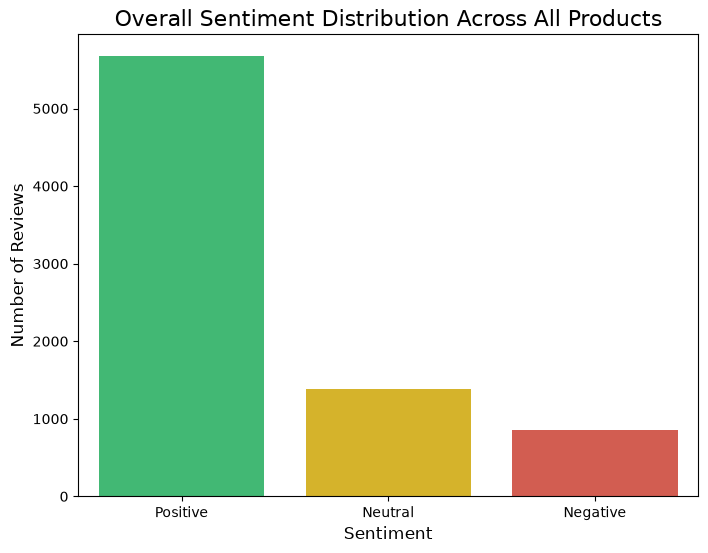


Products: 798 | Reviews: 7917

Distribution of review counts per product:
count    798.000000
mean       9.921053
std        4.230502
min        1.000000
25%        9.000000
50%       10.000000
75%       10.000000
max       60.000000
Name: Review_Count, dtype: float64


In [6]:
print("📊 Starting data analysis and visualization...")

SENTIMENT_ORDER = ["Positive", "Neutral", "Negative"]
SENTIMENT_COLORS = {"Positive": "#2ecc71", "Neutral": "#f1c40f", "Negative": "#e74c3c"}

# --- Overall sentiment distribution ---
plt.figure(figsize=(8, 6))
sns.countplot(
    data=df,
    x="Sentiment",
    order=SENTIMENT_ORDER,
    hue="Sentiment",
    palette=SENTIMENT_COLORS,
    legend=False,
)
plt.title("Overall Sentiment Distribution Across All Products", fontsize=16)
plt.xlabel("Sentiment", fontsize=12)
plt.ylabel("Number of Reviews", fontsize=12)
plt.show()

# --- Per-product summary ---
# Review count and average rating per product
product_performance = df.groupby("Product").agg(
    Review_Count=("Product", "count"),
    Avg_Rating=("Rating", "mean"),
).reset_index()
product_performance["Avg_Rating"] = product_performance["Avg_Rating"].round(3)

# Sentiment distribution per product, as a percentage of that product's reviews.
# reindex() guarantees all three sentiment columns exist, so the table always has the same schema.
sentiment_pct = df.groupby(["Product", "Sentiment"]).size().unstack(fill_value=0)
sentiment_pct = sentiment_pct.reindex(columns=SENTIMENT_ORDER, fill_value=0)
sentiment_pct = sentiment_pct.div(sentiment_pct.sum(axis=1), axis=0).mul(100).round(2)
sentiment_pct.columns = [f"Pct_{col}" for col in sentiment_pct.columns]

summary_table = product_performance.merge(sentiment_pct, on="Product", how="left").fillna(0)

print(f"\nProducts: {len(summary_table)} | Reviews: {len(df)}")
print("\nDistribution of review counts per product:")
print(summary_table["Review_Count"].describe())

## **Step 5: Fair Product Ranking**

Ranking by the raw average rating is misleading: a product with a single 5-star review would beat a product with 10 reviews averaging 4.9. To make the ranking fair, we apply two rules:

1. **Minimum reviews:** products with fewer than `MIN_REVIEWS` reviews stay in the summary table but are **not ranked**.
2. **Bayesian (weighted) average:** each product's average is pulled toward the global mean rating, and the fewer reviews a product has, the stronger the pull.

$$\text{Weighted Rating} = \frac{v \cdot R + m \cdot C}{v + m}$$

where $v$ is the product's number of reviews, $R$ its average rating, $C$ the global mean rating, and $m$ = `PRIOR_WEIGHT` (the number of "virtual" reviews at the global mean).

Ties are broken by review count (more reviews first), then alphabetically by product name, so the ranking is always deterministic. The two parameters can be tuned: check the review-count distribution printed in Step 4 and adjust them if needed.

Global mean rating: 3.984
Ranked products: 781 of 798 (minimum 5 reviews)

--- Product Performance Summary (ranked first) ---
                                     Product  Review_Count  Avg_Rating  Pct_Positive  Pct_Neutral  Pct_Negative  Weighted_Rating  Eligible  Rank
0             Facial Moiturizing Lotion - PM            10        5.00         100.0          0.0           0.0            4.661      True     1
1                              Minyak Zaitun            20        4.80          95.0          5.0           0.0            4.637      True     2
2                              Acne Solution             9        5.00         100.0          0.0           0.0            4.637      True     3
3                      Facial Treatment Mask             9        5.00         100.0          0.0           0.0            4.637      True     4
4    Teatree Care Solution Essential Mask EX             9        5.00         100.0          0.0           0.0            4.637      True     5
..  

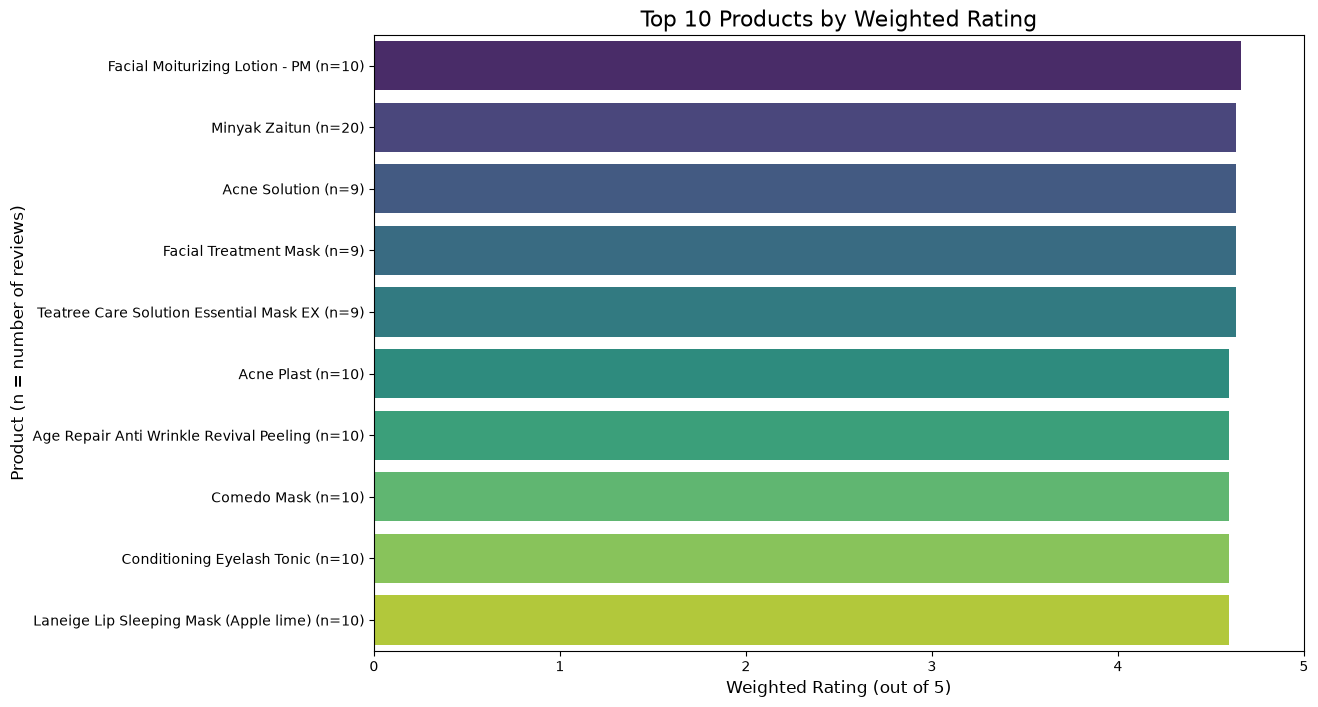

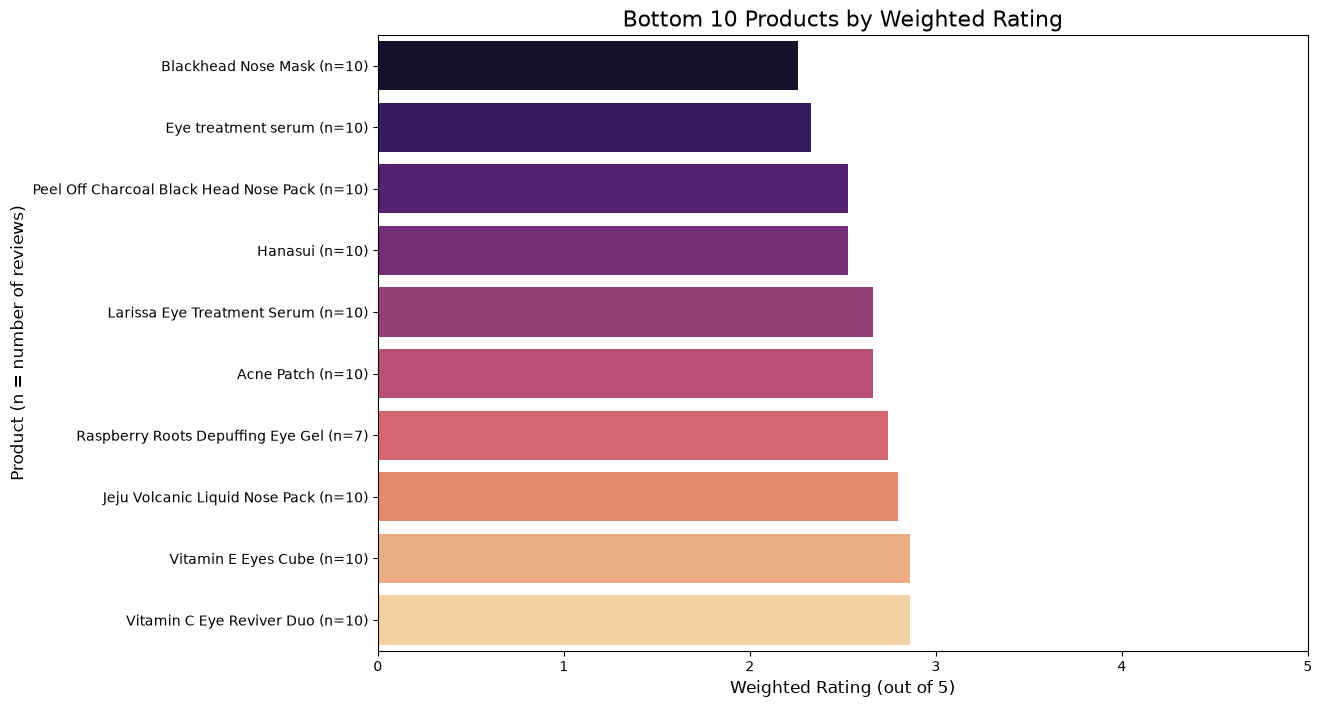

In [7]:
# --- Fair ranking parameters (tunable) ---
MIN_REVIEWS = 5    # products with fewer reviews are not ranked
PRIOR_WEIGHT = 5   # strength of the pull toward the global mean rating

global_mean_rating = df["Rating"].mean()

# Bayesian (weighted) average rating
summary_table["Weighted_Rating"] = (
    (summary_table["Review_Count"] * summary_table["Avg_Rating"] + PRIOR_WEIGHT * global_mean_rating)
    / (summary_table["Review_Count"] + PRIOR_WEIGHT)
).round(3)
summary_table["Eligible"] = summary_table["Review_Count"] >= MIN_REVIEWS

# Eligible products first, ordered by weighted rating, then review count, then name
summary_table = summary_table.sort_values(
    by=["Eligible", "Weighted_Rating", "Review_Count", "Product"],
    ascending=[False, False, False, True],
).reset_index(drop=True)

# Rank 1 = best. Products below the minimum review count get no rank.
summary_table["Rank"] = pd.Series(range(1, len(summary_table) + 1)).where(summary_table["Eligible"]).astype("Int64")

ranked = summary_table[summary_table["Eligible"]]
top_10_products = ranked.head(10)
bottom_10_products = ranked.tail(10).iloc[::-1]  # worst product first

print(f"Global mean rating: {global_mean_rating:.3f}")
print(f"Ranked products: {len(ranked)} of {len(summary_table)} (minimum {MIN_REVIEWS} reviews)")
if len(ranked) < 20:
    print("⚠️ Fewer than 20 ranked products: the top 10 and bottom 10 lists may overlap.")

print("\n--- Product Performance Summary (ranked first) ---")
print(summary_table)


def plot_weighted_rating(data, title, palette):
    """Draw a horizontal bar chart of weighted rating per product, with the review count in each label."""
    data = data.assign(Label=data["Product"] + " (n=" + data["Review_Count"].astype(str) + ")")
    plt.figure(figsize=(12, 8))
    sns.barplot(data=data, x="Weighted_Rating", y="Label", hue="Label", palette=palette, legend=False)
    plt.title(title, fontsize=16)
    plt.xlabel("Weighted Rating (out of 5)", fontsize=12)
    plt.ylabel("Product (n = number of reviews)", fontsize=12)
    plt.xlim(0, 5)
    plt.show()


plot_weighted_rating(top_10_products, "Top 10 Products by Weighted Rating", "viridis")
plot_weighted_rating(bottom_10_products, "Bottom 10 Products by Weighted Rating", "magma")

## **Step 6: Initialize the AI Model**

This step sets up the connection to Google Gemini using the `google-genai` SDK. The API key is loaded securely from a `.env` file in the project directory. Create the file and add your API key under the name `GEMINI_API_KEY`. Make sure the `.env` file is included in `.gitignore` to prevent accidentally exposing your API key.

In [8]:
from google import genai
from dotenv import load_dotenv
import os

# Gemini model used to summarize the reviews
MODEL_NAME = "gemini-3.6-flash"

# Load environment variables from .env
load_dotenv()

# Read the API key from environment variables
api_key = os.getenv("GEMINI_API_KEY")

if not api_key:
    raise ValueError("GEMINI_API_KEY is not set in the .env file.")

# Create the Gemini client
client = genai.Client(api_key=api_key)

## **Step 7: Summarize Reviews with AI**

The functions below use the AI model to summarize the main reasons behind positive sentiment (top 3 ranked products) and negative sentiment (bottom 3 ranked products). Each result is printed **and** stored in the `ai_summaries` list, so it can be exported for the dashboard in Step 8.

**Note:** Run the prompt a few times to get the best summaries. Reviews are randomly sampled, so results can vary between runs. Re-run Step 8 after you are happy with the summaries.

In [9]:
print("🧠 Starting AI summarization...")

MAX_REVIEWS_PER_PROMPT = 30

PROMPT_TEMPLATE = """
You are a market research analyst who specializes in distilling the key points from customer reviews.
Based on the collection of product reviews with "{sentiment}" sentiment below, identify and summarize the 3 most frequently mentioned reasons.
The reviews are written in Indonesian. Write your answer in English.

YOUR TASK:
Reply ONLY with a numbered list. Each item must be a very short phrase that gets straight to the point, exactly like the example below.

IMPORTANT RULES:
- DO NOT add extra explanations.
- DO NOT add an introduction or a closing sentence.
- DO NOT quote parts of the reviews.
- DO NOT repeat the title or any instructions.

Perfect example answer:
1. Long-lasting moisturizing effect.
2. Lightweight texture that absorbs quickly.
3. Soothing scent that is not overpowering.

Here are the reviews:
- {reviews}

Summary of the 3 main reasons:
"""


def summarize_reasons(reviews, sentiment_label):
    """Summarize the 3 main reasons behind a sentiment using Gemini. Returns (text, error)."""
    # If there are too many reviews, take a random sample to keep the prompt short and efficient
    if len(reviews) > MAX_REVIEWS_PER_PROMPT:
        reviews = pd.Series(reviews).sample(MAX_REVIEWS_PER_PROMPT).tolist()

    prompt = PROMPT_TEMPLATE.format(sentiment=sentiment_label, reviews="\n- ".join(reviews))

    try:
        response = client.models.generate_content(model=MODEL_NAME, contents=prompt)
        return response.text.strip(), None
    except Exception as e:
        return None, str(e)


def summarize_products(products, sentiment, group, icon, theme):
    """Summarize one sentiment for each product, print it, and return structured records."""
    records = []
    for position, row in enumerate(products.itertuples(), start=1):
        print(f"\n{icon} Summarizing {theme} for product: '{row.Product}'")

        reviews = df[(df["Product"] == row.Product) & (df["Sentiment"] == sentiment)]["Review"].tolist()
        text, error = (None, None)
        if reviews:
            text, error = summarize_reasons(reviews, sentiment.upper())
            print(text if text else f"Error while summarizing: {error}")
            status = "ok" if text else "error"
        else:
            print(f"No {sentiment.lower()} reviews available to summarize.")
            status = "no_reviews"

        # Split the numbered list ("1. ...", "2. ...") into separate points
        points = re.findall(r"^\s*\d+[.)]\s*(.+?)\s*$", text or "", flags=re.MULTILINE)

        records.append({
            "group": group,                       # "top" or "bottom"
            "group_position": position,           # 1 = best of the top group / worst of the bottom group
            "product": row.Product,
            "rank": int(row.Rank),                # overall rank (1 = best)
            "review_count": int(row.Review_Count),
            "avg_rating": float(row.Avg_Rating),
            "weighted_rating": float(row.Weighted_Rating),
            "sentiment": sentiment,
            "sentiment_review_count": len(reviews),
            "reviews_used": min(len(reviews), MAX_REVIEWS_PER_PROMPT),
            "summary_text": text,
            "summary_points": points,
            "status": status,
            "error": error,
            "model": MODEL_NAME,
            "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        })
    return records


ai_summaries = []

# Top 3 ranked products (positive sentiment)
print("\n--- Top Products (Positive Sentiment) ---")
ai_summaries += summarize_products(ranked.head(3), "Positive", "top", "✨", "praise")

# Bottom 3 ranked products (negative sentiment), worst first
print("\n\n--- Worst Products (Negative Sentiment) ---")
ai_summaries += summarize_products(ranked.tail(3).iloc[::-1], "Negative", "bottom", "⚠️", "complaints")

🧠 Starting AI summarization...

--- Top Products (Positive Sentiment) ---

✨ Summarizing praise for product: 'Facial Moiturizing Lotion - PM'
1. Lightweight, fast-absorbing, and non-sticky texture.
2. Gentle and non-comedogenic for sensitive, acne-prone skin.
3. Simple formula that effectively restores the skin barrier.

✨ Summarizing praise for product: 'Minyak Zaitun'
1. Deeply moisturizing effect for dry skin.
2. Pleasant and relaxing aroma.
3. Versatile and multi-purpose usability.

✨ Summarizing praise for product: 'Acne Solution'
1. Fast and effective acne drying.
2. Brightening effect for glowing skin.
3. Affordable price with great results.


--- Worst Products (Negative Sentiment) ---

⚠️ Summarizing complaints for product: 'Blackhead Nose Mask'
1. Ineffective at removing blackheads.
2. Weak peel-off strength.
3. Strong and unpleasant scent.

⚠️ Summarizing complaints for product: 'Eye treatment serum'
1. Ineffective with no visible results.
2. Causes a stinging or burning sen

## **Step 8: Export Results for the Dashboard**

This step saves everything the dashboard needs into the `dashboard_data/` folder. The dashboard can then load these files directly, with no need to re-run the analysis or call the AI model.

| File | Contents | Likely dashboard use |
|---|---|---|
| `reviews_clean.csv` | One row per cleaned review: `Product`, `SkinCond_Age`, `PostDate`, `Review`, `Rating`, `Review_Truncated`, `Sentiment`, `SkinType`, `AgeGroup`, `Recommended`, `Review_Length` | Review explorer, filters by product, sentiment, skin type, age group, and date; trends over time |
| `product_summary.csv` | One row per product: `Product`, `Review_Count`, `Avg_Rating`, `Pct_Positive`, `Pct_Neutral`, `Pct_Negative`, `Weighted_Rating`, `Eligible`, `Rank` | Ranking table, top/bottom 10 charts, product comparison |
| `ai_summaries.json` | AI-summarized praise (top 3) and complaints (bottom 3), with rank, ratings, review counts, model name, and timestamp | Product insight cards |
| `overall_stats.json` | Totals, average rating, sentiment and rating distributions, date range, ranking parameters, dataset and model info, and the `preprocessing` log from Step 3 | KPI tiles, overall charts, methodology notes |

**Privacy note:** `UserName` and the raw `Recommend` text (which contains the username) are **not** exported. The `Recommended` column keeps only the True/False signal, and phone numbers, `@handles`, links and e-mail addresses inside the review text are masked in Step 3 (unless you switched `MASK_PII` off).

In [10]:
OUTPUT_DIR = Path("dashboard_data")
OUTPUT_DIR.mkdir(exist_ok=True)


def json_default(obj):
    """Convert numpy / pandas scalars to plain Python types for JSON."""
    return obj.item() if hasattr(obj, "item") else str(obj)


# 1) Cleaned reviews (without usernames)
reviews_export = df.drop(columns=["UserName", "Recommend"]).copy()
reviews_export["PostDate"] = reviews_export["PostDate"].dt.strftime("%Y-%m-%d")
reviews_export.to_csv(OUTPUT_DIR / "reviews_clean.csv", index=False)

# 2) Product summary with weighted rating and rank
summary_table.to_csv(OUTPUT_DIR / "product_summary.csv", index=False)

# 3) AI summaries
with open(OUTPUT_DIR / "ai_summaries.json", "w", encoding="utf-8") as f:
    json.dump(ai_summaries, f, ensure_ascii=False, indent=2, default=json_default)

# 4) Overall statistics and metadata
sentiment_counts = df["Sentiment"].value_counts().reindex(SENTIMENT_ORDER, fill_value=0)
rating_counts = df["Rating"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

overall_stats = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "dataset": DATASET_ID,
    "ai_model": MODEL_NAME,
    "total_reviews": len(df),
    "total_products": int(df["Product"].nunique()),
    "ranked_products": len(ranked),
    "avg_rating": round(float(df["Rating"].mean()), 3),
    "sentiment_counts": sentiment_counts.to_dict(),
    "sentiment_pct": (sentiment_counts / sentiment_counts.sum() * 100).round(2).to_dict(),
    "rating_counts": {str(k): v for k, v in rating_counts.to_dict().items()},
    "date_range": {
        "start": df["PostDate"].min().strftime("%Y-%m-%d") if df["PostDate"].notna().any() else None,
        "end": df["PostDate"].max().strftime("%Y-%m-%d") if df["PostDate"].notna().any() else None,
    },
    "preprocessing": preprocessing_log,
    "ranking": {
        "method": "Bayesian (weighted) average rating",
        "min_reviews": MIN_REVIEWS,
        "prior_weight": PRIOR_WEIGHT,
        "global_mean_rating": round(float(global_mean_rating), 3),
    },
}
with open(OUTPUT_DIR / "overall_stats.json", "w", encoding="utf-8") as f:
    json.dump(overall_stats, f, ensure_ascii=False, indent=2, default=json_default)